# 经营预测：从历史记录到下一周安排
真实UCI日租借数据，七节跟做。起点2012-11-18，预测随后七天。

先手算一行，再看程序；先运行一个起点，再运行多轮。完整原始数据已在`data/raw`，直接打开即可。

## 1｜读入数据，认清日期与单位（课件5—15页）
cnt是每天完成的租借次数，等于casual与registered之和。先保留一行对应一天的结构；日期排序后核对自然日连续。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analysis import calendar_names, calendar_row, forecast, fit_model, rolling, metrics, MODEL_NAMES
ROOT = Path.cwd()
assert (ROOT / 'data/raw/day.csv').is_file(), '请从学生包解压目录打开Notebook'
df = pd.read_csv('data/raw/day.csv', parse_dates=['dteday'])
print('原始形状:', df.shape)
df = df.sort_values('dteday').set_index('dteday')
display(df[['cnt','casual','registered','holiday','weekday']].head())

原始形状: (731, 16)


,cnt,casual,registered,holiday,weekday
dteday,,,,,
2011-01-01,985,331,654,0,6
2011-01-02,801,131,670,0,0
2011-01-03,1349,120,1229,0,1
2011-01-04,1562,108,1454,0,2
2011-01-05,1600,82,1518,0,3


In [2]:
dates = pd.date_range(df.index.min(), df.index.max(), freq='D', name='dteday')
assert df.index.is_unique and df.index.equals(dates)
assert df.cnt.notna().all()
assert (df.cnt == df.casual + df.registered).all()
assert (df.weekday == (df.index.dayofweek + 1) % 7).all()
origin = pd.Timestamp('2012-11-18')
train = df.loc[:origin].copy()
future_dates = pd.date_range(origin + pd.Timedelta(days=1), periods=7)
future_calendar = df.loc[future_dates, ['holiday']].copy()
print('当前训练天数:', len(train))
display(future_calendar.assign(weekday=future_dates.day_name(), month=future_dates.month))

当前训练天数: 688


,holiday,weekday,month
2012-11-19,0,Monday,11
2012-11-20,0,Tuesday,11
2012-11-21,0,Wednesday,11
2012-11-22,1,Thursday,11
2012-11-23,0,Friday,11
2012-11-24,0,Saturday,11
2012-11-25,0,Sunday,11


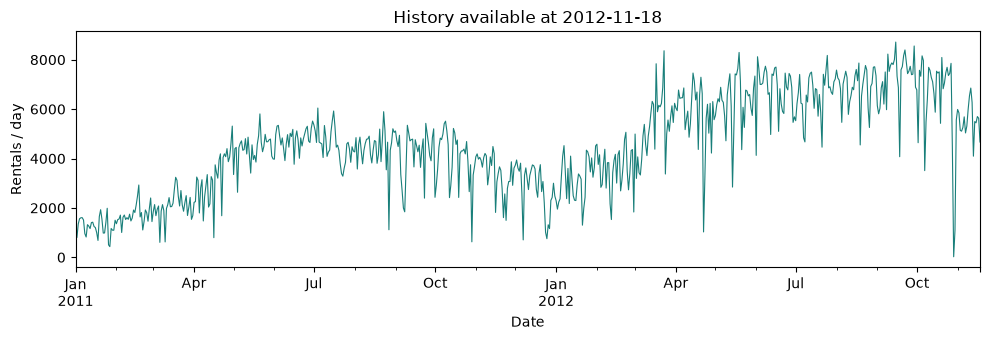

In [3]:
fig, ax = plt.subplots(figsize=(10,3.5))
train.cnt.plot(ax=ax, color='#197f7a', linewidth=0.8)
ax.set(xlabel='Date', ylabel='Rentals / day', title='History available at 2012-11-18')
plt.tight_layout(); plt.show()

## 2｜三个简单基准（课件16—29页）
最后一天：每个目标日沿用起点最后一次观测。上周同一天：目标日期向前7天取实际。最近7天均值：七个数相加除以7，再填入本次七行。

本次目标是随后7天，所以这些上周对应日都已经发生。先算11月19日对应的11月12日，再展开七行。

In [4]:
same_weekday = [train.loc[d-pd.Timedelta(days=7), 'cnt'] for d in future_dates]
mean7 = train.cnt.tail(7).mean()
baselines = pd.DataFrame({'last_value':train.cnt.iloc[-1],
                         'same_weekday':same_weekday, 'mean7':mean7}, index=future_dates)
print('最近7天合计:', train.cnt.tail(7).sum(), '平均:', mean7)
display(baselines.round(1))

最近7天合计: 37299 平均: 5328.428571428572


,last_value,same_weekday,mean7
2012-11-19,4669,6269,5328.4
2012-11-20,4669,4094,5328.4
2012-11-21,4669,5495,5328.4
2012-11-22,4669,5445,5328.4
2012-11-23,4669,5698,5328.4
2012-11-24,4669,5629,5328.4
2012-11-25,4669,4669,5328.4


## 3｜日历回归（课件30—49页）
先定义每列：常数、距2011-01-01的天数/100、周二至周日6列、2月至12月11列、H。周一和1月为参照，共20列。

holiday=1按原作者DCHR日历；周末由星期另行记录。11月22日同时是周四、11月、H=1。逐项输入乘自己的系数后相加。

In [5]:
# 展开输入生成函数，便于逐列修改。
def classroom_calendar_row(date, holiday):
    date = pd.Timestamp(date)
    return ([1., (date-pd.Timestamp('2011-01-01')).days/100]
            + [float(date.dayofweek == j) for j in range(1,7)]
            + [float(date.month == j) for j in range(2,13)]
            + [float(holiday)])
X = np.array([classroom_calendar_row(d,r.holiday) for d,r in train.iterrows()])
y = train.cnt.to_numpy()
beta_calendar = np.linalg.lstsq(X,y,rcond=None)[0]
print('X形状:',X.shape)
display(pd.DataFrame({'term':calendar_names(),'coefficient':beta_calendar}).round(6))

X形状: (688, 20)


,term,coefficient
0,constant,787.927013
1,trend100,639.690221
2,weekday_1,109.232696
3,weekday_2,153.034755
4,weekday_3,304.494022
5,weekday_4,299.708882
6,weekday_5,243.397496
7,weekday_6,-81.420803
8,month_2,253.925963
9,month_3,1104.812050


In [6]:
d = pd.Timestamp('2012-11-22')
row = np.array(classroom_calendar_row(d, 1))
contributions = pd.DataFrame({'term':calendar_names(), 'input':row,
                             'coefficient':beta_calendar, 'contribution':row*beta_calendar})
display(contributions.loc[row != 0].round(3))
print('合计预测:', row @ beta_calendar)
no_holiday = np.array(classroom_calendar_row(d, 0))
print('H从0到1的模型输入差:', row @ beta_calendar - no_holiday @ beta_calendar)

,term,input,coefficient,contribution
0,constant,1.00,787.927,787.927
1,trend100,6.91,639.690,4420.259
4,weekday_3,1.00,304.494,304.494
17,month_11,1.00,387.865,387.865
19,holiday,1.00,-221.969,-221.969


合计预测: 5678.576220800145
H从0到1的模型输入差: -221.96911836873915


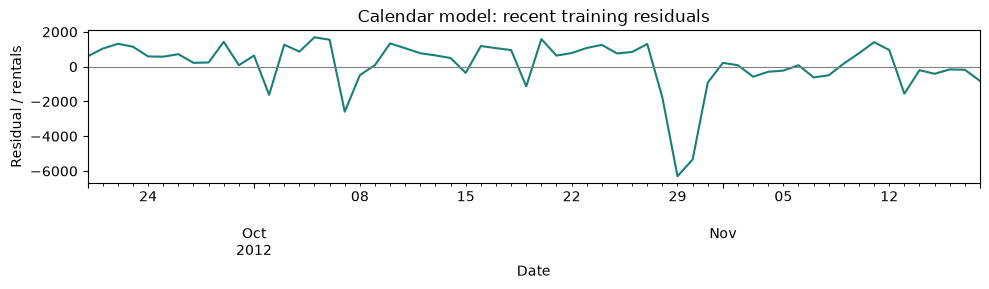

In [7]:
residual = pd.Series(y-X@beta_calendar, index=train.index)
fig, ax = plt.subplots(figsize=(10,3))
residual.tail(60).plot(ax=ax,color='#197f7a')
ax.axhline(0,color='gray',linewidth=0.8)
ax.set(xlabel='Date',ylabel='Residual / rentals',title='Calendar model: recent training residuals')
plt.tight_layout(); plt.show()

## 4｜lag1与AR(1)（课件50—60页）
滞后1天把昨天的次数放到今天这一行。AR(1)的相加式是`c + phi × lag1`。688天历史形成687对。

连续7天在同一个起点计算：第一天lag1用11月18日实际；第二天开始接前一步预测。递归指后一步使用前一步的计算结果。

In [8]:
ar_frame = train.assign(lag1=train.cnt.shift(1)).dropna()
display(ar_frame[['cnt','lag1']].tail(7))
X_ar = np.column_stack([np.ones(len(ar_frame)), ar_frame.lag1])
beta_ar = np.linalg.lstsq(X_ar,ar_frame.cnt,rcond=None)[0]
c, phi = beta_ar
print('687行，两项系数:', beta_ar)
previous = float(train.cnt.iloc[-1])
ar_steps = []
for h,d in enumerate(future_dates,1):
    pred = c+phi*previous
    ar_steps.append({'date':d,'h':h,'lag1':previous,
                     'source':'observed' if h==1 else 'previous forecast','prediction':pred})
    previous = pred
ar_steps = pd.DataFrame(ar_steps)
display(ar_steps.round(3))
print('固定水平 c/(1-phi):', c/(1-phi))

,cnt,lag1
dteday,,
2012-11-12,6269,6852.0
2012-11-13,4094,6269.0
2012-11-14,5495,4094.0
2012-11-15,5445,5495.0
2012-11-16,5698,5445.0
2012-11-17,5629,5698.0
2012-11-18,4669,5629.0


687行，两项系数: [685.33045116   0.84987619]


C:\Users\Administrator\AppData\Local\Temp\ipykernel_127544\459272779.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ar_steps.round(3))


,date,h,lag1,source,prediction
0,2012-11-19,1,4669.000,observed,4653.402
1,2012-11-20,2,4653.402,previous forecast,4640.146
2,2012-11-21,3,4640.146,previous forecast,4628.880
3,2012-11-22,4,4628.880,previous forecast,4619.306
4,2012-11-23,5,4619.306,previous forecast,4611.168
5,2012-11-24,6,4611.168,previous forecast,4604.253
6,2012-11-25,7,4604.253,previous forecast,4598.375


固定水平 c/(1-phi): 4565.101520017636


## 5｜日历＋lag1＋lag7（课件61—70页）
lag7向前查7天，保留最近同星期的业务量。组合模型先计算日历部分，再加`phi1 × lag1 + phi7 × lag7`。对齐后保留681行、22列。

In [9]:
frame = train.assign(lag1=train.cnt.shift(1),lag7=train.cnt.shift(7)).dropna()
X_arx = np.array([classroom_calendar_row(d,r.holiday)+[r.lag1,r.lag7]
                  for d,r in frame.iterrows()])
beta_arx = np.linalg.lstsq(X_arx,frame.cnt,rcond=None)[0]
print('X形状:',X_arx.shape)
display(frame[['cnt','lag1','lag7']].tail(7))
display(pd.DataFrame({'term':calendar_names()+['lag1','lag7'],
                      'coefficient':beta_arx}).tail(3).round(6))

X形状: (681, 22)


,cnt,lag1,lag7
dteday,,,
2012-11-12,6269,6852.0,5259.0
2012-11-13,4094,6269.0,5686.0
2012-11-14,5495,4094.0,5035.0
2012-11-15,5445,5495.0,5315.0
2012-11-16,5698,5445.0,5992.0
2012-11-17,5629,5698.0,6536.0
2012-11-18,4669,5629.0,6852.0


,term,coefficient
19,holiday,-170.576328
20,lag1,0.385179
21,lag7,0.028532


In [10]:
# 只在预测结束后再接未来实际值；循环内future_calendar只有H与日期。
history = train.cnt.to_dict()
trace = []
for d,r in future_calendar.iterrows():
    lag1 = history[d-pd.Timedelta(days=1)]
    lag7 = history[d-pd.Timedelta(days=7)]
    calendar_part = np.array(classroom_calendar_row(d,r.holiday)) @ beta_arx[:-2]
    part1, part7 = beta_arx[-2]*lag1, beta_arx[-1]*lag7
    pred = calendar_part+part1+part7
    trace.append({'date':d,'lag1':lag1,'lag7':lag7,'calendar':calendar_part,
                   'lag1_part':part1,'lag7_part':part7,'prediction':pred})
    history[d] = pred
trace = pd.DataFrame(trace)
display(trace.round(3))
assert np.allclose(trace.prediction, [r['prediction'] for r in forecast(train,future_calendar,'arx')])

C:\Users\Administrator\AppData\Local\Temp\ipykernel_127544\819393300.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(trace.round(3))


,date,lag1,lag7,calendar,lag1_part,lag7_part,prediction
0,2012-11-19,4669.000,6269,3285.054,1798.402,178.870,5262.326
1,2012-11-20,5262.326,4094,3393.770,2026.939,116.812,5537.521
2,2012-11-21,5537.521,5495,3383.284,2132.938,156.786,5673.008
3,2012-11-22,5673.008,5445,3343.615,2185.125,155.359,5684.099
4,2012-11-23,5684.099,5698,3460.188,2189.397,162.578,5812.163
5,2012-11-24,5812.163,5629,3410.761,2238.725,160.609,5810.095
6,2012-11-25,5810.095,4669,3125.462,2237.928,133.218,5496.607


In [11]:
alternate = future_calendar.copy()
alternate.loc['2012-11-22','holiday'] = 0
with_h = pd.DataFrame(forecast(train,future_calendar,'arx')).set_index('date').prediction
without_h = pd.DataFrame(forecast(train,alternate,'arx')).set_index('date').prediction
display(pd.DataFrame({'H_original':with_h,'H22_zero':without_h,
                      'difference':with_h-without_h}).round(3))

,H_original,H22_zero,difference
date,,,
2012-11-19,5262.326,5262.326,0.000
2012-11-20,5537.521,5537.521,0.000
2012-11-21,5673.008,5673.008,0.000
2012-11-22,5684.099,5854.676,-170.576
2012-11-23,5812.163,5877.865,-65.702
2012-11-24,5810.095,5835.402,-25.307
2012-11-25,5496.607,5506.355,-9.748


## 6｜误差、验证与测试（课件71—86页）
误差=实际−当时预测。绝对误差保留距离。MAE把绝对误差平均；RMSE把误差平方、平均、开方。先用上周同一天方案手算一周。

In [12]:
actual = df.loc[future_dates,'cnt'].to_numpy()
e = actual-np.array(same_weekday)
error_table = pd.DataFrame({'prediction':same_weekday,'actual':actual,
                           'error':e,'absolute_error':np.abs(e)},index=future_dates)
display(error_table)
print('MAE:',np.mean(np.abs(e)), 'RMSE:',np.sqrt(np.mean(e**2)))
small = np.array([200,-200])
print('两天小例子: 平均方向',small.mean(),'MAE',np.abs(small).mean(),
      'RMSE',np.sqrt(np.mean(small**2)))

,prediction,actual,error,absolute_error
2012-11-19,6269,5499,-770,770
2012-11-20,4094,5634,1540,1540
2012-11-21,5495,5146,-349,349
2012-11-22,5445,2425,-3020,3020
2012-11-23,5698,3910,-1788,1788
2012-11-24,5629,2277,-3352,3352
2012-11-25,4669,2424,-2245,2245


MAE: 1866.2857142857142 RMSE: 2127.358321621308
两天小例子: 平均方向 0.0 MAE 200.0 RMSE 200.0


每轮从历史里模拟一次预测：将起点逐周向后移动，每轮完整预测随后7天。验证10轮用于按MAE选择当前方案，再固定规则，报告后面8轮测试。

`analysis.py`中的rolling先生成预测，然后接目标日期实际值；forecast的未来参数只接收日期与holiday。可以打开脚本逐行查看。

In [13]:
validation_origins = pd.date_range('2012-08-26','2012-10-28',freq='7D')
test_origins = pd.date_range('2012-11-04','2012-12-23',freq='7D')
validation = rolling(df,validation_origins)
validation_metrics = pd.DataFrame(metrics(validation))
display(validation_metrics[['name','n','mae','rmse']].round(3))
selected = validation_metrics.sort_values('mae').iloc[0].model
print('验证按MAE选定:',MODEL_NAMES[selected])
test = rolling(df,test_origins)
display(pd.DataFrame(metrics(test))[['name','n','mae','rmse']].round(3))

,name,n,mae,rmse
0,最后一天,70,1309.114,1724.645
1,上周同一天,70,1119.771,1751.282
2,最近7天均值,70,1010.527,1583.954
3,日历回归,70,1047.898,1484.121
4,AR(1),70,1763.439,2014.606
5,日历＋滞后1、7天,70,1027.192,1422.428


验证按MAE选定: 最近7天均值


,name,n,mae,rmse
0,最后一天,56,1409.214,1643.666
1,上周同一天,56,1474.071,1986.469
2,最近7天均值,56,1254.531,1611.768
3,日历回归,56,1201.154,1755.797
4,AR(1),56,1247.552,1449.239
5,日历＋滞后1、7天,56,1148.264,1635.780


,count,mean
h,,
1,8,981.196
2,8,1071.107
3,8,883.607
4,8,1137.339
5,8,955.232
6,8,1715.107
7,8,2038.125


,date,prediction,actual,error
98,2012-11-19,5328.429,5499.0,170.571
99,2012-11-20,5328.429,5634.0,305.571
100,2012-11-21,5328.429,5146.0,-182.429
101,2012-11-22,5328.429,2425.0,-2903.429
102,2012-11-23,5328.429,3910.0,-1418.429
103,2012-11-24,5328.429,2277.0,-3051.429
104,2012-11-25,5328.429,2424.0,-2904.429


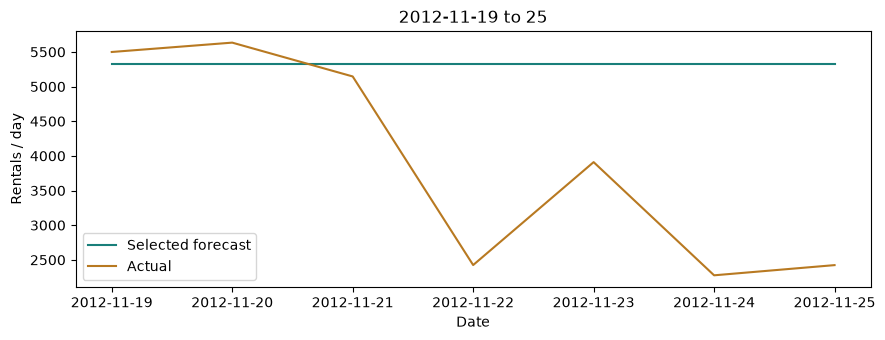

In [14]:
chosen = test.loc[test.model==selected]
display(chosen.groupby('h').absolute_error.agg(['count','mean']).round(3))
main = chosen.loc[chosen.origin==origin.strftime('%Y-%m-%d')]
display(main[['date','prediction','actual','error']].round(3))
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(pd.to_datetime(main.date),main.prediction,label='Selected forecast',color='#197f7a')
ax.plot(pd.to_datetime(main.date),main.actual,label='Actual',color='#b87921')
ax.set(xlabel='Date',ylabel='Rentals / day',title='2012-11-19 to 25');ax.legend()
plt.tight_layout();plt.show()

## 7｜自己的项目简报（课件87—90页）
保留七行预测、输入来源、验证选择和测试误差，写一项运营准备动作与下一次更新时间。可使用`forecast-brief-template.md`。

给编程助手的分步任务：
1. 读取day.csv，打印日期检查和cnt定义对应列。
2. 生成未来七天日历，逐项解释H、星期参照、月份参照。
3. 输出基准、日历逐项贡献、lag1/lag7与七步递归表。
4. 先运行一个起点核对，再滚动验证，按MAE选方案，最后测试。
5. 导出预测表、误差表和一段运营准备说明。

先把这一版完整跑通，再提出一个新输入，例如节前或节后。写清取值定义与提前可用的来源。

In [15]:
out = ROOT/'outputs'; out.mkdir(exist_ok=True)
validation.to_csv(out/'validation-predictions.csv',index=False)
test.to_csv(out/'test-predictions.csv',index=False)
trace.to_csv(out/'notebook-recursive-trace.csv',index=False)
print('已导出预测表与递归表；请填写自己的预测简报。')

已导出预测表与递归表；请填写自己的预测简报。


数据：Fanaee-T (2013), UCI Bike Sharing, DOI 10.24432/C5W894，CC BY 4.0。完整方法及原始日历链接见SOURCES.md。